In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Per-iterate fixed-point metrics. This ships as `fp_metrics.npz`, produced by replaying the
# saved optimisation checkpoints with `track_fp.py` (the offline path). The in-loop path
# (Force_Minimizer with `track_islands = true`) records the same arrays into the run's HDF5
# `/iterations/fp` group. See README.md to regenerate either way.
NPZ_FILE = "fp_metrics.npz"

# Tracking a magnetic island across a SPECTRE optimisation

`spectre.fixed_points.FixedPointTracker` follows the magnetic axis and one island fixed-point
chain as an equilibrium is optimised. This example tracks the **3/5 island chain** in volume 3 of a
fixed-boundary **NCSX** equilibrium (`Nfp = 3`, so `iota = 3/5` with `island_n = 3`,
`island_m = 5`) across 21 force-minimisation iterates. The equilibrium is generated from the
public `wout_li383_low_res_reference.nc` VMEC output (see `README.md`).

The 3/5 resonant surface starts just inside the neighbouring volume, so the tracker reports `no_fp`
at iterate 0 and then discovers the chain in volume 3 from iterate 1 on, as the equilibrium relaxes
and the surface moves into the tracked volume. Below we plot how the magnetic axis and the island
O-point move, and how the island's Greene residue evolves. The metrics were produced with the
offline `track_fp.py` path; the in-loop path (`Force_Minimizer` with `track_islands = true`) records
the same quantities into the run's HDF5 `/iterations/fp` group.

In [7]:
d = np.load(NPZ_FILE)
iters = d["iteration_indices"].astype(int)
axis_rz = d["axis_rz"]
island_rz = d["island_rz"]  # tracked O-point; NaN on no_fp iterates
residue = d["greene_residue"]  # Greene residue R = (2 - tr M) / 4
iota = d["iota"]
iota_rel = d["iota_rel"]
no_fp = d["no_fp"]

found = ~no_fp  # iterates where the island fixed point was located
imin, imax = np.nanmin(iota[found]), np.nanmax(iota[found])
rmin, rmax = np.nanmin(residue[found]), np.nanmax(residue[found])
print(
    f"{len(iters)} iterates; island located in {found.sum()} of them "
    f"(iter {iters[found][0]} .. {iters[found][-1]}), no_fp in {no_fp.sum()}."
)
print(f"iota (located): {imin:.6f} .. {imax:.6f}  (3/5 = {3 / 5:.6f})")
print(f"Greene residue (located): {rmin:.2e} .. {rmax:.2e}  (0 < R < 1 => elliptic O-point)")


21 iterates; island located in 20 of them (iter 1 .. 20), no_fp in 1.
iota (located): 0.600000 .. 0.600000  (3/5 = 0.600000)
Greene residue (located): 3.95e-02 .. 1.91e-01  (0 < R < 1 => elliptic O-point)


## 1 — Magnetic axis position over optimisation iterates

The magnetic axis is tracked as a period-1 fixed point. It drifts as the equilibrium is optimised,
while `Z` stays near 0 (stellarator symmetry).


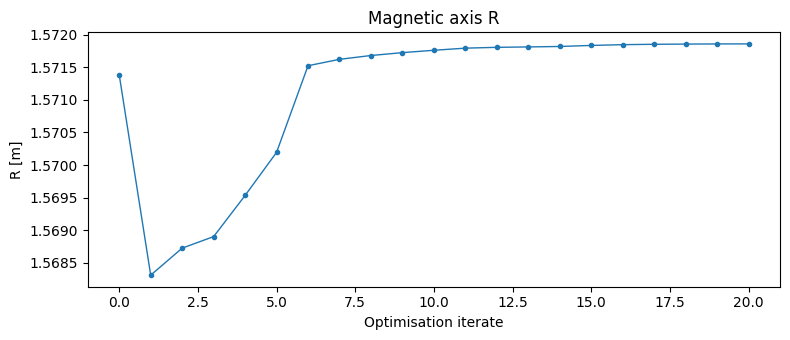

In [8]:
axis_found = ~np.isnan(axis_rz[:, 0])
fig, ax = plt.subplots(figsize=(8, 3.5))

ax.plot(iters[axis_found], axis_rz[axis_found, 0], "o-", ms=3, lw=1)
ax.set(xlabel="Optimisation iterate", ylabel="R [m]", title="Magnetic axis R")

fig.tight_layout()
plt.show()


## 2 — Island O-point position and Greene residue over iterates

`island_rz` is the tracked O-point (island centre). Only the iterates where the chain was located
in volume 3 are plotted (iterate 0 is `no_fp`). Left: the O-point's path in $(R, Z)$, coloured by
optimisation iterate. Right: the **Greene residue** $R = (2 - \mathrm{tr}\,M)/4$;
$0 < R < 1$ is elliptic (an O-point). The chain stays elliptic once found.


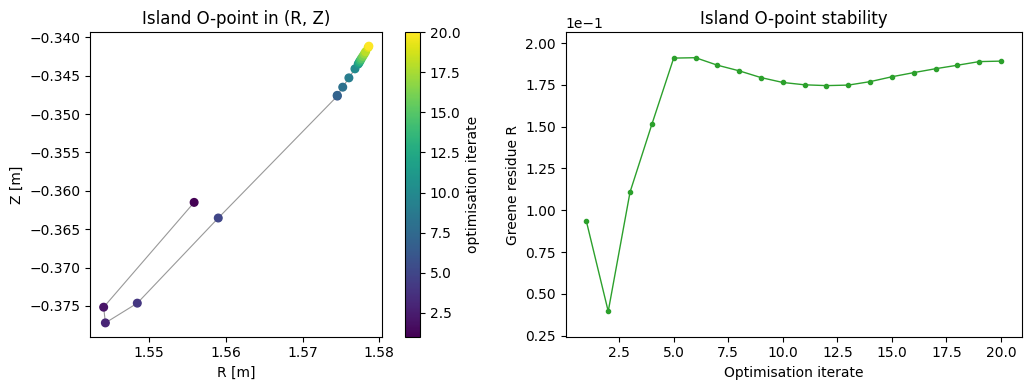

Final Greene residue: 1.892e-01  (elliptic O-point)
Final iota: 0.600000  (3/5 = 0.600000, rel err 1.8e-07)


In [9]:
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11, 4))

sc = axA.scatter(
    island_rz[found, 0], island_rz[found, 1], c=iters[found], cmap="viridis", s=30, zorder=3
)
axA.plot(island_rz[found, 0], island_rz[found, 1], "-", lw=0.8, color="0.6", zorder=2)
axA.set(xlabel="R [m]", ylabel="Z [m]", title="Island O-point in (R, Z)")
axA.set_aspect("equal")
fig.colorbar(sc, ax=axA, label="optimisation iterate")

res = residue[found]
axB.plot(iters[found], res, "o-", ms=3, lw=1, color="tab:green")
ymin, ymax = float(np.nanmin(res)), float(np.nanmax(res))
pad = 0.1 * (ymax - ymin) if ymax > ymin else max(abs(ymin) * 0.1, 1e-3)
axB.set_ylim(ymin - pad, ymax + pad)
axB.ticklabel_format(axis="y", style="scientific", scilimits=(0, 0))
axB.set(xlabel="Optimisation iterate", ylabel="Greene residue R", title="Island O-point stability")

fig.tight_layout()
plt.show()

print(f"Final Greene residue: {residue[found][-1]:.3e}  (elliptic O-point)")
print(f"Final iota: {iota[found][-1]:.6f}  (3/5 = {3 / 5:.6f}, rel err {iota_rel[found][-1]:.1e})")


## 3 — Interactive use: `find_axis` and `find_fixed_point` on a single equilibrium

Both finders are also methods of `SPECTREout`, so a single equilibrium can be inspected with no
tracking setup. This cell runs on `tests/test_files/freeb_ncsx.h5`, a small converged
free-boundary NCSX equilibrium committed for the test suite, which carries a 3/5 island chain
in volume 3 (and a 6/11 chain in volume 2). It needs an installed `spectre` and takes about a
minute (the no-guess call scans the volume).


In [12]:
from spectre import SPECTREout
from spectre.fixed_points import FixedPointClassifier

out = SPECTREout("../../../tests/test_files/freeb_ncsx.h5")

# The magnetic axis (a period-1 fixed point), found by the dedicated axis finder.
rax, zax, sax, thax = out.find_axis()
print(f"axis: R = {rax:.6f} m, Z = {zax:+.2e} m")

# Discover the 3/5 chain in volume 3 -- no seed needed. return_all=True returns every
# converged member so they can be overlaid on the Poincare plot below.
members = out.find_fixed_point(3, 5, return_all=True)
clf = FixedPointClassifier(out, vol=3, m=5)
print(f"found {len(members)} members of the 3/5 chain")
for i, fp in enumerate(members):
    g = clf.greene(fp.s, fp.theta)
    greene = f"{g['residue']:.3e} ({g['kind']})" if g is not None else "n/a"
    print(
        f"  [{i}] R = {fp.R:.4f} m, Z = {fp.Z:+.4f} m, residual = {fp.residual:.1e} m, "
        f"Greene = {greene}"
    )

# Or polish a single point from an (R, Z) guess, e.g. read off a Poincare plot. A rough
# guess may need more than the fail-fast default budget (the in-loop tracker uses 100).
polished = out.find_fixed_point(3, 5, guess_rz=(members[0].R, members[0].Z + 0.005), maxfev=100)
g = clf.greene(polished.s, polished.theta)
greene = f"{g['residue']:.3e} ({g['kind']})" if g is not None else "n/a"
print(f"polished from guess: ({polished.R:.6f}, {polished.Z:+.6f}), "
      f"converged = {polished.converged}, Greene = {greene}")


axis: R = 1.599796 m, Z = -1.79e-09 m
found 5 members of the 3/5 chain
  [0] R = 1.5011 m, Z = -0.0000 m, residual = 4.5e-16 m, Greene = 3.449e-02 (O)
  [1] R = 1.2599 m, Z = +0.5197 m, residual = 6.0e-16 m, Greene = 3.449e-02 (O)
  [2] R = 1.2599 m, Z = -0.5197 m, residual = 2.4e-15 m, Greene = 3.449e-02 (O)
  [3] R = 1.5380 m, Z = +0.4543 m, residual = 4.7e-15 m, Greene = 3.449e-02 (O)
  [4] R = 1.5380 m, Z = -0.4543 m, residual = 5.8e-14 m, Greene = 3.449e-02 (O)
polished from guess: (1.501120, -0.000000), converged = True, Greene = 3.449e-02 (O)


### Use an H5 file that has a /poincare group for a better plot 

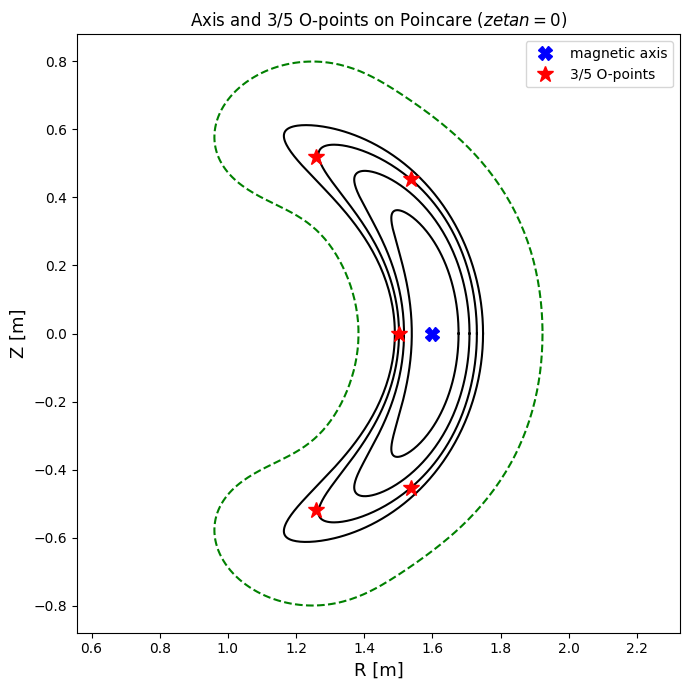

In [13]:
# Overlay the magnetic axis and the located 3/5 O-points on the Poincare section at zetan = 0.
fig, ax = plt.subplots(figsize=(7, 7))
out.plot_infaces(ax=ax, color="k", zetan=0.0, prange="full")
out.plot_poincare(ax=ax, c="C0", zetan=0.0, ms=1.2, prange="full")
ax.plot(rax, zax, "bX", ms=10, zorder=5, label="magnetic axis")
for fp in members:
    ax.plot(fp.R, fp.Z, "r*", ms=12, zorder=5)
ax.plot([], [], "r*", ms=12, label="3/5 O-points")
ax.set_title(r"Axis and 3/5 O-points on Poincare ($zetan = 0$)")
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()
